# Практическое задание №3. Задача классификации на Kaggle с помощью логистической регрессии

Цель: разработать алгоритм машинного обучения, который позволит классифицировать место залежей нефти и газа (ONSHORE / OFFSHORE).

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, MultiLabelBinarizer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from catboost import CatBoostRegressor
from lightgbm import LGBMRegressor
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import ElasticNet, Lasso, Ridge
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.base import BaseEstimator, TransformerMixin
import pandas as pd
import numpy as np
import re
from collections import Counter
from sklearn.model_selection import RandomizedSearchCV
import pandas as pd

RANDOM_STATE = 42
CURRENT_YEAR = 2025


In [2]:
train = pd.read_excel("datasets/dz5/train.xlsx")
test = pd.read_excel("datasets/dz5/test.xlsx")

print(train.head())
train.info()
train.describe()

   Unnamed: 0      предмет                                                ФИО  \
0           0   matematika  Репетитор по математике  Емельянова Марина Вла...   
1           1   matematika  Репетитор по математике  Назарова Анастасия Ан...   
2           2  informatika  Репетитор по информатике Мотроненко Инна Конст...   
3           3   matematika  Репетитор по математике  Логинова Елизавета Ал...   
4           4   matematika  Репетитор по математике  Харланов Олег Викторо...   

                                     tutor_head_tags  tutor_rating  \
0  ['Школьная программа', 'Подготовка к ЕГЭ', 'По...           5.0   
1  ['Школьная программа', 'Подготовка к ЕГЭ', 'По...           4.0   
2  ['Школьная программа', 'Подготовка к ЕГЭ', 'По...           0.0   
3  ['Школьная программа', 'Математический анализ'...           4.0   
4  ['Школьная программа', 'Подготовка к ЕГЭ', 'По...           0.0   

   tutor_reviews                                        description  \
0              2     

,Unnamed: 0,tutor_rating,tutor_reviews,mean_price
count,4548.000000,3959.000000,4548.000000,4548.000000
mean,2273.500000,1.895933,2.989006,16.197949
std,1313.038842,2.280103,8.516939,10.485108
min,0.000000,0.000000,0.000000,0.041667
25%,1136.750000,0.000000,0.000000,10.000000
50%,2273.500000,0.000000,0.000000,15.000000
75%,3410.250000,4.000000,2.000000,20.888889
max,4547.000000,5.000000,152.000000,100.000000


In [3]:
df = train.copy()  # Создаем копию для дальнейшей работы

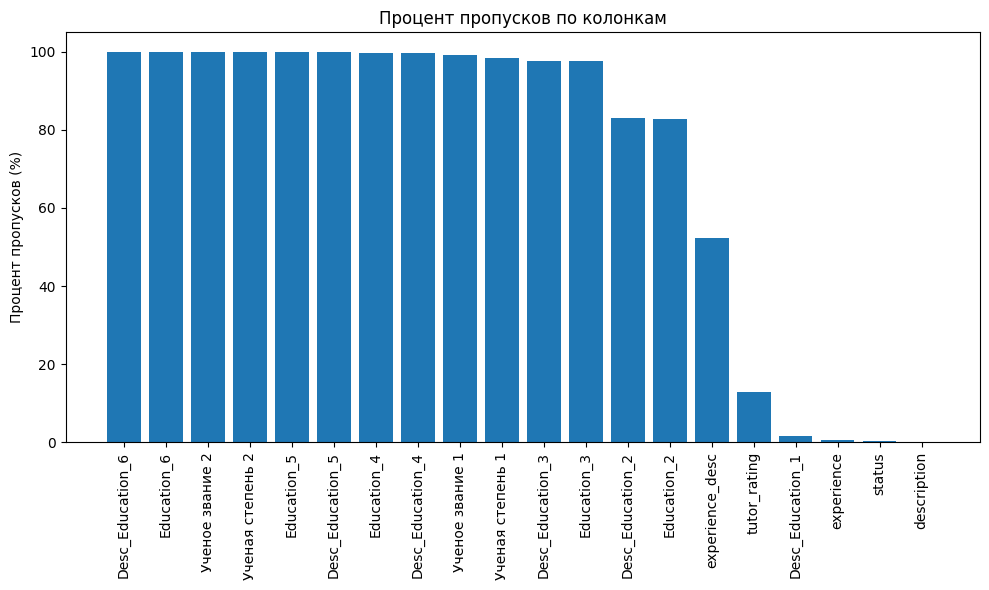

In [4]:
missing = train.isnull().sum()
missing_percent = (missing / len(train)) * 100

missing_train_prepared = pd.DataFrame({
    'Колонка': missing.index,
    'Пропущено': missing.values,
    'Процент': missing_percent.values
}).sort_values('Пропущено', ascending=False)

# Отображаем только колонки с пропусками
missing_train_prepared = missing_train_prepared[missing_train_prepared['Пропущено'] > 0]

plt.figure(figsize=(10, 6))
plt.bar(missing_train_prepared['Колонка'], missing_train_prepared['Процент'])
plt.xticks(rotation=90)
plt.title('Процент пропусков по колонкам')
plt.ylabel('Процент пропусков (%)')
plt.tight_layout()
plt.show()

## Анализ данных

Набор данных содержит **26 признаков** и 4548 наблюдений. 

**Типы признаков:** есть как количественные (например, Depth), так и категориальные (например, Basin).

**Пропущенные значения:** Education_2+, Desc_Education_2+, Ученая степень 2, Ученое звание 2 сильно разрежены. Есть ~50 процентов пропусков в описании опыта. Есть менее 20 процентов пропусков в рейтинге репититора и незначительное кол-во пропусков в Desc_Education_1, experience, status, description.

**Целевая переменная:** mean_price - средняя цена за минуту. 

На нулевом этапе была выполнена базовая техническая очистка данных, необходимая для корректного проведения разведочного анализа и последующей предобработки. Из набора данных был удалён неинформативный технический признак Unnamed: 0, представляющий собой индекс строк. Пропущенные значения в числовом признаке tutor_rating были заполнены медианным значением, так как доля пропусков невелика. Категориальный признак status был приведён к единому виду с использованием значения unknown, а текстовое поле description заполнено пустыми строками. Списковые признаки (tutor_head_tags, categories), изначально представленные в виде строк, были распарсены в списки, что позволило в дальнейшем корректно анализировать и агрегировать информацию о направлениях подготовки и категориях учеников.

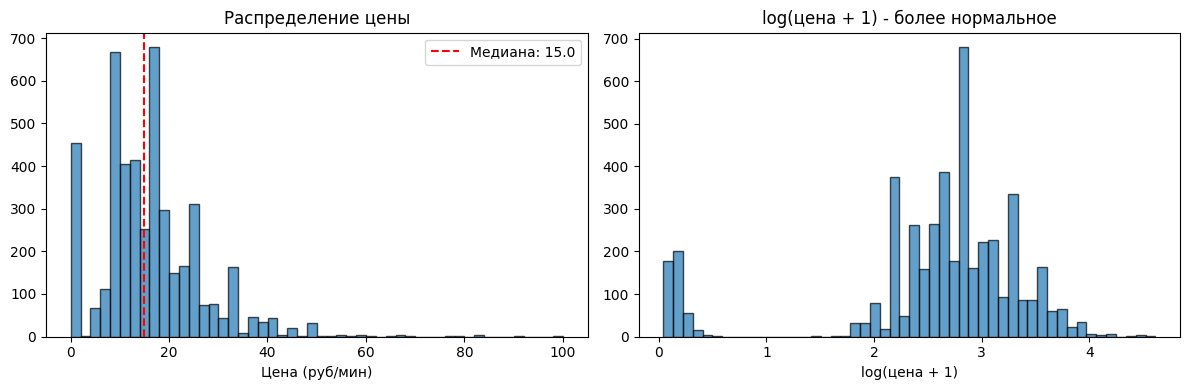

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# Распределение цены
ax1.hist(train['mean_price'], bins=50, edgecolor='black', alpha=0.7)
ax1.set_title('Распределение цены')
ax1.set_xlabel('Цена (руб/мин)')
ax1.axvline(train['mean_price'].median(), color='red', linestyle='--', 
            label=f'Медиана: {train["mean_price"].median():.1f}')
ax1.legend()

# Логарифмированное распределение
ax2.hist(np.log1p(train['mean_price']), bins=50, edgecolor='black', alpha=0.7)
ax2.set_title('log(цена + 1) - более нормальное')
ax2.set_xlabel('log(цена + 1)')

plt.tight_layout()
plt.show()

plt.show()


**Распределение целевой переменной**

Распределение цены имеет выраженный правый хвост с выбросами. Логарифмическая трансформация снижает асимметрию, но распределение остается неравномерным. Оптимальным выбором являются модели, устойчивые к такому смещению (например, Random Forest). Для линейных моделей следует применять логарифмирование целевой переменной.

### Предварительная очистка данных

- **Удаление служебных колонок** (`Unnamed: 0`): эти столбцы не несут аналитической информации и только засоряют данные.
- **Очистка текстовых колонок**:
  - заменяем пропуски на пустые строки, чтобы избежать ошибок при обработке текста;
  - удаляем лишние пробелы и нормализуем текст к нижнему регистру — это упрощает поиск и сравнение строк;
- **Замена стандартных формулировок «не предоставил информацию»** в колонках `description`, `experience_desc`, `Education_1`: помогает корректно считать пустые значения, не учитывая формальные заглушки.
- **Числовые колонки** (`tutor_rating`, `tutor_reviews`, `mean_price`) приводятся к числовому типу, пропуски заполняются нулями, чтобы модели могли работать без ошибок;
- **Преобразование опыта работы** (`experience`) в число лет из текста: позволяет использовать опыт как числовой признак.
- **Конвертация строковых списков** (`tutor_head_tags`, `categories`) в Python-списки: упрощает дальнейшую генерацию бинарных признаков наличия тегов/категорий.
- **Обработка рейтинга**: пропуски заменяются на 0, тип приводится к целому числу, чтобы корректно использовать рейтинг как числовую переменную.


In [6]:
class TutorDataCleaner(BaseEstimator, TransformerMixin):
    """Класс для первичной обработки исходных данных, без генерации новых фич"""

    def __init__(self):
        super().__init__()

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        df = X.copy()

        # --- Удаляем ненужные служебные колонки ---
        drop_cols = ['Unnamed: 0']
        df.drop(columns=[c for c in drop_cols if c in df.columns], inplace=True)

        # --- Список текстовых колонок ---
        text_cols = [
            'ФИО', 'description', 'experience_desc',
            'Education_1', 'Desc_Education_1',
            'Education_2', 'Desc_Education_2',
            'Education_3', 'Desc_Education_3',
            'Education_4', 'Desc_Education_4',
            'Education_5', 'Desc_Education_5',
            'Education_6', 'Desc_Education_6',
            'status', 'Ученое звание 1', 'Ученое звание 2',
            'Ученая степень 1', 'Ученая степень 2', 'experience'
        ]

        # --- Очистка текстовых полей ---
        for col in text_cols:
            if col in df.columns:
                # заменяем NaN на пустую строку
                df[col] = df[col].fillna('').astype(str)
                # удаляем лишние пробелы в начале/конце
                df[col] = df[col].str.strip()
                # заменяем множественные пробелы внутри текста на один
                df[col] = df[col].apply(lambda x: re.sub(r'\s+', ' ', x))
                # приводим к нижнему регистру
                df[col] = df[col].str.lower()

        # --- Специальная замена дефолтного текста для описаний ---
        for desc_col in ['description', 'experience_desc', 'Education_1']:
            if desc_col in df.columns:
                df[desc_col] = df[desc_col].replace(
                    'репетитор не предоставил о себе дополнительных сведений', ''
                ).replace(
                    'Репетитор не предоставил информацию об опыте работы', ''
                ).replace(
                    'репетитор не предоставил информацию об образовании', ''
                )

        # --- Числовые колонки ---
        num_cols = ['tutor_rating', 'tutor_reviews', 'mean_price']
        for col in num_cols:
            if col in df.columns:
                df[col] = pd.to_numeric(df[col], errors='coerce').fillna(0)

        # --- Преобразуем experience в число лет, если это текст ---
        if 'experience' in df.columns:
            df['experience'] = df['experience'].str.extract(r'(\d+)').fillna(0).astype(int)

        # --- Преобразуем tutor_head_tags и categories из строк в списки ---
        list_cols = ['tutor_head_tags', 'categories']
        for col in list_cols:
            if col in df.columns:
                df[col] = df[col].apply(lambda x: eval(x) if x and isinstance(x, str) else [])

        # рейтинг на самом деле представлен только целыми числами, при чем пропуски скорее всего означают отсутствие оценки
        df['tutor_rating'] = df['tutor_rating'].fillna(0).astype(int)
        return df
        

In [7]:
TutorDataCleaner().transform(train).head(5)

,предмет,ФИО,tutor_head_tags,tutor_rating,tutor_reviews,description,experience_desc,Education_1,Desc_Education_1,Education_2,...,status,experience,Desc_Education_5,Desc_Education_6,Education_5,Education_6,Ученая степень 2,Ученое звание 2,categories,mean_price
0,matematika,репетитор по математике емельянова марина влад...,"[Школьная программа, Подготовка к ЕГЭ, Подгото...",5,2,,,томский государственный университет им. в.в. к...,"год окончания: 1990, факультет: механико-матем...",,...,университетский преподаватель,31,,,,,,,"[Школьники с 5 по 9 класс, Школьники с 10 по 1...",16.666667
1,matematika,репетитор по математике назарова анастасия анд...,"[Школьная программа, Подготовка к ЕГЭ, Подгото...",4,7,,,вологодский государственный педагогический уни...,"год окончания: 2017, факультет: факультет прик...",череповецкий государственный университет,...,школьный преподаватель,8,,,,,,,"[Школьники с 5 по 9 класс, Школьники с 10 по 1...",11.666667
2,informatika,репетитор по информатике мотроненко инна конст...,"[Школьная программа, Подготовка к ЕГЭ, Подгото...",0,0,"выезд за город: балашиха-1, балашиха-2, балаши...","московская школа (учитель информатики, эксперт...",московский городской педагогический университет,"год окончания: 2008, факультет: математический...",московский городской педагогический университе...,...,школьный преподаватель,11,,,,,,,"[Школьники с 5 по 9 класс, Школьники с 10 по 1...",23.333333
3,matematika,репетитор по математике логинова елизавета але...,"[Школьная программа, Математический анализ, По...",4,19,"здравствуйте! меня зовут елизавета, окончила б...",,санкт-петербургский государственный университет,"год окончания: 2021, факультет: физический фак...",,...,частный преподаватель,5,,,,,,,"[Школьники с 1 по 4 класс, Школьники с 5 по 9 ...",0.116667
4,matematika,репетитор по математике харланов олег викторов...,"[Школьная программа, Подготовка к ЕГЭ, Подгото...",0,0,"целеустремленный, ориентирован на результат. в...","преподавателем мое основное образование ""магис...",приазовский государственный технический универ...,"год окончания: 2005, факультет: энергетический...",,...,частный преподаватель,19,,,,,,,"[Школьники с 5 по 9 класс, Школьники с 10 по 1...",16.666667


### Генерация новых признаков

Класс `TutorFeatureEngineer` создает новые признаки для модели на основе очищенных данных.

1. **Демографические признаки** — пол, преподавание математики
2. **Количественные метрики** — число тегов, категорий, образований, длина описаний
3. **Бинарные флаги** — наличие рейтинга, отзывов, ЕГЭ/ОГЭ, работы со школами и вузами
4. **Ключевые слова в описании** — 10 тематических категорий (опыт, образование, ЕГЭ, онлайн и др.)
5. **Сегментация репетиторов** — разделение на группы по предмету, опыту и отзывам
6. **Комбинированные признаки** — взаимодействия между ключевыми характеристиками

Этап преобразует сырые текстовые данные в структурированные числовые признаки, готовые для анализа и обучения моделей.

In [8]:
class TutorFeatureEngineer(BaseEstimator, TransformerMixin):
    TOP_10_UNIS = [
        'московский государственный университет','мгу',
        'санкт-петербургский государственный университет','спбгу',
        'высшая школа экономики','вшэ',
        'мгту им','баумана',
        'московский физико-технический институт','мфти',
        'мифи','национальный исследовательский ядерный университет','ранхигс'
    ]

    def __init__(self, features_list=None, drop_intermediate=True):
        self.features_list = features_list
        self.drop_intermediate = drop_intermediate
        super().__init__()

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        df = X.copy()
        
        # Проверяем наличие необходимых колонок
        required_cols = ['предмет', 'tutor_head_tags', 'categories', 'description']
        missing_cols = [col for col in required_cols if col not in df.columns]
        if missing_cols:
            raise ValueError(f"Отсутствуют необходимые колонки: {missing_cols}")
        
        # Создаем новые признаки
        df = self._feature_subject(df)
        df = self._feature_gender(df)
        df = self._feature_tags(df)
        df = self._feature_rating_reviews(df)
        df = self._feature_description(df)
        df = self._feature_education(df)
        df = self._feature_experience(df)
        df = self._feature_categories(df)
        df = self._feature_additional(df)
        df = self._create_segments(df)
        df = self._feature_keywords(df)
        df = self._drop_raw_and_leakage(df)

        if self.features_list is not None:
            # Проверяем, что все запрошенные признаки существуют
            available_features = [f for f in self.features_list if f in df.columns]
            missing_features = [f for f in self.features_list if f not in df.columns]
            if missing_features:
                print(f"Предупреждение: отсутствуют признаки: {missing_features}")
            df = df[available_features]
        
        return df

    def _drop_raw_and_leakage(self, df):
        """
        Удаляем сырые, текстовые и утечные признаки
        """
        drop_cols = [
            # персональные / идентификаторы
            'ФИО',
            'предмет',

            # сырые тексты
            'description',
            'experience_desc',

            # сырое образование
            'Education_1_clean',
            'Education_1', 'Desc_Education_1',
            'Education_2', 'Desc_Education_2',
            'Education_3', 'Desc_Education_3',
            'Education_4', 'Desc_Education_4',
            'Education_5', 'Desc_Education_5',
            'Education_6', 'Desc_Education_6',
            'Ученое звание 1', 'Ученое звание 2',
            'Ученая степень 1', 'Ученая степень 2',

            # списки (если уже есть агрегаты)
            'categories',
            'tutor_head_tags',
        ]
        existing = [c for c in drop_cols if c in df.columns]
        return df.drop(columns=existing)


    def _feature_subject(self, df):
        df['is_math'] = (df['предмет'] == 'matematika').astype(int)
        return df

    def _feature_gender(self, df):
        def extract_gender(name):
            try:
                parts = str(name).split()
                if len(parts) >= 2:
                    first_name = parts[-3]
                    first_name = first_name.lower()
                    # Проверяем окончания женских имен
                    return int(first_name.endswith(('а', 'я', 'ь')))
            except:
                pass
            return 0  # по умолчанию мужской
        
        df['gender'] = df['ФИО'].apply(extract_gender)
        return df

    def _feature_tags(self, df):
        # Создаем список тегов если его еще нет
        if 'tutor_head_tags_list' not in df.columns:
            def safe_eval(x):
                try:
                    if isinstance(x, list):
                        return x
                    elif pd.isna(x):
                        return []
                    else:
                        return eval(str(x))
                except:
                    return []
            df['tutor_head_tags_list'] = df['tutor_head_tags'].apply(safe_eval)
        
        df['num_tags'] = df['tutor_head_tags_list'].apply(len)
        df['has_ege_oge'] = df['tutor_head_tags_list'].apply(
            lambda x: int(any('егэ' in str(tag).lower() or 'огэ' in str(tag).lower() for tag in x))
        )
        df['has_school_program'] = df['tutor_head_tags_list'].apply(
            lambda x: int(any('школ' in str(tag).lower() for tag in x))
        )
        return df

    def _feature_rating_reviews(self, df):
        # Убедимся, что это числовые колонки
        if 'tutor_rating' in df.columns:
            df['tutor_rating'] = pd.to_numeric(df['tutor_rating'], errors='coerce').fillna(0)
        
        if 'tutor_reviews' in df.columns:
            df['tutor_reviews'] = pd.to_numeric(df['tutor_reviews'], errors='coerce').fillna(0)
        
        df['has_rating'] = (df['tutor_rating'] > 0).astype(int)
        df['has_reviews'] = (df['tutor_reviews'] > 0).astype(int)
        df['log_reviews'] = np.log1p(df['tutor_reviews'])
        
        # Дополнительные признаки на основе рейтинга и отзывов
        df['reviews_per_rating'] = np.where(
            df['tutor_rating'] > 0,
            df['tutor_reviews'] / df['tutor_rating'],
            0
        )
        return df

    def _feature_description(self, df):
        # Проверяем наличие колонок
        if 'description' not in df.columns:
            df['description'] = ''
        
        if 'experience_desc' not in df.columns:
            df['experience_desc'] = ''
        
        # Длина описаний
        df['desc_len'] = df['description'].str.len()
        df['exp_desc_len'] = df['experience_desc'].str.len()
        
        # Логарифмированные версии
        df['desc_len_log'] = np.log1p(df['desc_len'])
        df['exp_desc_len_log'] = np.log1p(df['exp_desc_len'])
        
        return df

    def _feature_education(self, df):
        # --- Собираем столбцы образования ---
        edu_cols = [f'Education_{i}' for i in range(1, 7) if f'Education_{i}' in df.columns]
        desc_cols = [f'Desc_Education_{i}' for i in range(1, 7) if f'Desc_Education_{i}' in df.columns]

        #  Количество образований

        df['num_educations'] = (df[edu_cols] != '').sum(axis=1) if edu_cols else 0
        df['main_university'] = df['Education_1'] if 'Education_1' in df.columns else ''

        
        def has_top10_uni(row):
            for col in edu_cols:
                text = row[col]
                if text and any(uni in text for uni in self.TOP_10_UNIS):
                    return 1
            return 0

        df['is_top10_uni'] = df.apply(has_top10_uni, axis=1)
            
        # --- Извлечение факультета из описаний ---
        def extract_faculty(text):
            if not isinstance(text, str) or text.strip() == '':
                return 'unknown'

            text = text.lower()

            faculty_map = {
                'математ': 'математика',
                'прикладн': 'прикладная математика',
                'физмат': 'физмат',
                'физик': 'физика',
                'информ': 'информатика',
                'программ': 'информатика',
                'компьют': 'информатика',
                'эконом': 'экономика',
                'педагог': 'педагогика',
                'технич': 'технический',
                'хими': 'химия'
            }

            for key, value in faculty_map.items():
                if key in text:
                    return value

            return 'other'

        if desc_cols:
            df['faculty'] = df[desc_cols].apply(
                lambda row: next(
                    (extract_faculty(x) for x in row if isinstance(x, str) and x.strip()),
                    'unknown'
                ),
                axis=1
            )
        else:
            df['faculty'] = 'unknown'

        # --- Признак наличия факультета ---
        df['has_faculty'] = (df['faculty'] != 'unknown').astype(int)

        # --- Ученая степень / звание ---
        degree_cols = [c for c in [
            'Ученая степень 1', 'Ученое звание 1',
            'Ученая степень 2', 'Ученое звание 2'
        ] if c in df.columns]

        if degree_cols:
            df[degree_cols] = df[degree_cols].fillna('').astype(str)
            df['has_degree_title'] = (df[degree_cols] != '').any(axis=1).astype(int)
        else:
            df['has_degree_title'] = 0

        df.drop(columns='main_university', inplace=True)

        return df
    def _feature_experience(self, df):
        # Проверяем, есть ли колонка experience и преобразуем в число если нужно
        if 'experience' in df.columns:
            # Если это строка, извлекаем числа
            if df['experience'].dtype == 'object':
                df['experience'] = df['experience'].str.extract(r'(\d+)').fillna(0).astype(int)
            else:
                # Уже числовая, но заполняем пропуски
                df['experience'] = df['experience'].fillna(0)
        else:
            df['experience'] = 0
        
        df['has_experience'] = (df['experience'] > 0).astype(int)
        
        # Группы по опыту
        df['experience_group'] = pd.cut(
            df['experience'],
            bins=[-1, 0, 3, 10, 100],
            labels=['no_exp', 'junior', 'middle', 'senior']
        )
        return df

    def _feature_categories(self, df):
        # Создаем список категорий если его нет
        if 'categories_list' not in df.columns:
            def safe_eval_cats(x):
                try:
                    if isinstance(x, list):
                        return x
                    elif pd.isna(x):
                        return []
                    else:
                        return eval(str(x))
                except:
                    return []
            
            df['categories_list'] = df['categories'].apply(safe_eval_cats)
        
        df['num_categories'] = df['categories_list'].apply(len)
        df['has_school_students'] = df['categories_list'].apply(
            lambda x: int(any('школ' in str(cat).lower() for cat in x))
        )
        df['has_university_students'] = df['categories_list'].apply(
            lambda x: int(any('студент' in str(cat).lower() for cat in x))
        )
        return df
    
    def _feature_additional(self, df):
        # Комбинированные признаки
        df['has_additional_edu'] = (df['num_educations'] > 1).astype(int)
        
        # has_description_long - используем desc_len
        if 'desc_len' in df.columns:
            df['has_description_long'] = (df['desc_len'] > 50).astype(int)
        else:
            df['has_description_long'] = 0
        
        if 'log_reviews' in df.columns:
            df['has_any_reviews'] = (df['log_reviews'] > 0).astype(int)
        else:
            df['has_any_reviews'] = 0
        
        # Взаимодействия признаков
        if 'is_math' in df.columns and 'experience' in df.columns:
            df['math_experienced'] = df['is_math'] * df['experience']
        else:
            df['math_experienced'] = 0
        
        if 'is_math' in df.columns and 'has_any_reviews' in df.columns:
            df['info_with_reviews'] = (1 - df['is_math']) * df['has_any_reviews']
        else:
            df['info_with_reviews'] = 0
        
        # Более сложные комбинации
        if 'tutor_rating' in df.columns and 'log_reviews' in df.columns:
            df['rating_reviews_combo'] = df['tutor_rating'] * df['log_reviews']
        else:
            df['rating_reviews_combo'] = 0
        
        if 'num_educations' in df.columns and 'experience' in df.columns:
            df['edu_exp_combo'] = df['num_educations'] * df['experience']
        else:
            df['edu_exp_combo'] = 0
               
        return df

    def _create_segments(self, df):
        def create_segments(row):
            if row.get('is_math', 0) == 1:
                exp = row.get('experience', 0)
                if exp > 10:
                    return 'math_senior'
                elif exp > 3:
                    return 'math_middle'
                else:
                    return 'math_junior'
            else:
                has_reviews = row.get('has_any_reviews', 0)
                exp = row.get('experience', 0)
                if has_reviews == 1 and exp > 5:
                    return 'info_experienced'
                elif has_reviews == 1:
                    return 'info_with_reviews'
                else:
                    return 'info_newbie'
        
        df['segment'] = df.apply(create_segments, axis=1)
        return df

    def _feature_keywords(self, df):
        keywords = {
            'desc_has_experience': ['опыт', 'стаж', 'работал', 'работаю', 'преподавани'],
            'desc_has_education': ['образован', 'университет', 'институт', 'академия', 'высшее'],
            'desc_has_quality': ['качеств', 'профессионал', 'эксперт', 'специалист', 'опытн'],
            'desc_has_results': ['результат', 'успех', 'достижен', 'сдал', 'поступ'],
            'desc_has_ege': ['егэ', 'огэ', 'экзамен', 'подготовк'],
            'desc_has_individual': ['индивидуал', 'личный', 'персонал', 'учитыва'],
            'desc_has_online': ['онлайн', 'дистанцион', 'skype', 'zoom', 'telegram'],
            'desc_has_school': ['школ', 'ученик', 'класс', 'программ'],
            'desc_has_price': ['цена', 'стоимость', 'оплат', 'рубл', 'недорог'],
            'desc_has_free': ['бесплатн', 'тестов', 'пробн']
        }
        
        # Уже очищенный текст от cleaner
        desc_text = df['description'].fillna('').str.lower()
        
        for feature_name, words in keywords.items():
            pattern = '|'.join(words)
            df[feature_name] = desc_text.str.contains(pattern).astype(int)
        
        # Общее количество найденных ключевых слов
        keyword_cols = [col for col in df.columns if col.startswith('desc_has_')]
        if keyword_cols:
            df['total_keywords'] = df[keyword_cols].sum(axis=1)
        else:
            df['total_keywords'] = 0
        
        return df

In [9]:
TutorFeatureEngineer().transform(TutorDataCleaner().transform(train)).head(5)


,tutor_rating,tutor_reviews,status,experience,mean_price,is_math,gender,tutor_head_tags_list,num_tags,has_ege_oge,...,desc_has_education,desc_has_quality,desc_has_results,desc_has_ege,desc_has_individual,desc_has_online,desc_has_school,desc_has_price,desc_has_free,total_keywords
0,5,2,университетский преподаватель,31,16.666667,1,1,"[Школьная программа, Подготовка к ЕГЭ, Подгото...",3,1,...,0,0,0,0,0,0,0,0,0,0
1,4,7,школьный преподаватель,8,11.666667,1,1,"[Школьная программа, Подготовка к ЕГЭ, Подгото...",3,1,...,0,0,0,0,0,0,0,0,0,0
2,0,0,школьный преподаватель,11,23.333333,0,1,"[Школьная программа, Подготовка к ЕГЭ, Подгото...",3,1,...,0,0,1,1,1,0,1,0,0,5
3,4,19,частный преподаватель,5,0.116667,1,1,"[Школьная программа, Математический анализ, По...",8,1,...,1,0,0,1,0,0,1,0,1,5
4,0,0,частный преподаватель,19,16.666667,1,0,"[Школьная программа, Подготовка к ЕГЭ, Подгото...",3,1,...,0,0,1,1,0,0,1,0,0,3


In [10]:
def auto_detect_feature_types(df: pd.DataFrame,
                             target_col: str = 'mean_price',
                             cat_threshold: int = 20,
                             exclude_cols = None):

    if exclude_cols is None:
        exclude_cols = []

    # Исключаем целевой столбец и другие исключаемые столбцы
    analysis_cols = [col for col in df.columns
                    if col not in exclude_cols and col != target_col]

    # Инициализируем списки
    num_features = []
    cat_features = []
    bin_features = []
    lst_features = []
    other_features = []

    for col in analysis_cols:
        # Пропускаем пропущенные значения
        non_null = df[col].dropna()

        if len(non_null) == 0:
            other_features.append(col)
            continue

        if isinstance(non_null.iloc[0], (list, tuple)):
            lst_features.append(col)
            continue

        # Определяем тип данных
        dtype = df[col].dtype

        # Проверяем на бинарные признаки
        unique_vals = non_null.unique()

        # Признаки, содержащие только 0 и 1 (или True/False)
        if set(unique_vals).issubset({0, 1}) or set(unique_vals).issubset({True, False}):
            bin_features.append(col)

        # Категориальные признаки (строки или мало уникальных числовых значений)
        elif dtype == 'object' or dtype.name == 'category' or len(unique_vals) <= cat_threshold:
            cat_features.append(col)

        # Числовые признаки (целые или вещественные числа)
        elif np.issubdtype(dtype, np.number):
            num_features.append(col)

        # Все остальное
        else:
            other_features.append(col)

    return {
        'TARGET': [target_col] if target_col in df.columns else [],
        'NUM_FEATURES': num_features,
        'BIN_FEATURES': bin_features,
        'CAT_FEATURES': cat_features,
        'LST_FEATURES': lst_features,
        'OTHER_FEATURES': other_features
    }

In [11]:
# Получаем результат функции
feature_dict = auto_detect_feature_types(
    TutorFeatureEngineer().transform(TutorDataCleaner().transform(train))
)

# Распарсиваем в отдельные переменные
TARGET = feature_dict['TARGET'][0] if feature_dict['TARGET'] else None
NUM_FEATURES = feature_dict['NUM_FEATURES']
BIN_FEATURES = feature_dict['BIN_FEATURES']
CAT_FEATURES = feature_dict['CAT_FEATURES']
LST_FEATURES = feature_dict['LST_FEATURES']
OTHER_FEATURES = feature_dict['OTHER_FEATURES']

# Выводим информацию
print(f"TARGET: {TARGET}")
print(f"NUM_FEATURES: {len(NUM_FEATURES)} признаков")
print(f"BIN_FEATURES: {len(BIN_FEATURES)} признаков")
print(f"CAT_FEATURES: {len(CAT_FEATURES)} признаков")
print(f"LST_FEATURES: {len(LST_FEATURES)} признаков")
#feature_dict


TARGET: mean_price
NUM_FEATURES: 11 признаков
BIN_FEATURES: 26 признаков
CAT_FEATURES: 9 признаков
LST_FEATURES: 2 признаков


Классификация признаков для анализа и пайплайна
Признаки автоматически делятся на типы (числовые, бинарные, категориальные) для:
- анализа — разные типы требуют разных методов EDA
- предобработки — каждый тип обрабатывается в пайплайне ML по-своему.


In [12]:
def is_low_variation(series, threshold=0.95): 
    """Проверяет, если признак слишком однообразен (например, 95% одинаковых значений)""" 
    return series.value_counts(normalize=True).iloc[0] > threshold

In [13]:
def eda_numeric(df, numerical_features=NUM_FEATURES, target=TARGET, show_plots=True):
    print("\n=== ЧИСЛОВЫЕ ПРИЗНАКИ ===")
    num_corrs = []

    for col in numerical_features:
        if col not in df.columns:
            continue

        corr = df[[col, target]].corr().iloc[0, 1]
        num_corrs.append((col, corr))

        if show_plots:
            fig, ax = plt.subplots(1, 2, figsize=(12, 4))
            sns.histplot(df[col], kde=True, ax=ax[0])
            ax[0].set_title(col)
            sns.scatterplot(x=df[col], y=df[target], ax=ax[1], alpha=0.4)
            ax[1].set_title(f"{col} vs {target}")
            plt.tight_layout()
            plt.show()

    corr_matrix = df[numerical_features + [target]].corr()
    plt.figure(figsize=(12, 10))
    sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0)
    plt.show()
    print("\n= Корреляционная матрица числовых признаков =")
    print(corr_matrix)
    
    return pd.DataFrame(num_corrs, columns=["feature", "corr"]), num_corrs

def eda_binary(df, binary_features=BIN_FEATURES, target=TARGET, top_n=15):
    print("\n=== БИНАРНЫЕ ПРИЗНАКИ ===")
    bin_rows = []

    for col in binary_features:
        if col not in df.columns:
            continue

        vc = df[col].value_counts(normalize=True)
        corr = df[[col, target]].corr().iloc[0, 1]

        bin_rows.append({
            "feature": col,
            "share_1": vc.get(1, 0),
            "share_0": vc.get(0, 0),
            "corr": corr,
            "abs_corr": abs(corr)
        })

    bin_df = pd.DataFrame(bin_rows).sort_values("abs_corr", ascending=False)
    print(bin_df.head(top_n).to_string(index=False))
    
    bin_scores = [(r['feature'], r['corr']) for r in bin_rows]
    return bin_df, bin_scores

def eda_categorical(df, categorical_features=CAT_FEATURES, target=TARGET, top_n=15):
    print("\n=== КАТЕГОРИАЛЬНЫЕ ПРИЗНАКИ ===")
    cat_rows = []

    for col in categorical_features:
        if col not in df.columns:
            continue

        means = df.groupby(col)[target].mean()
        encoded = df[col].map(means)
        corr = np.corrcoef(encoded, df[target])[0, 1]

        vc = df[col].value_counts(normalize=True)

        cat_rows.append({
            "feature": col,
            "n_categories": df[col].nunique(),
            "top1_share": vc.iloc[0],
            "corr": corr,
            "abs_corr": abs(corr)
        })

    cat_df = pd.DataFrame(cat_rows).sort_values("abs_corr", ascending=False)
    print(cat_df.head(top_n).to_string(index=False))
    
    cat_scores = [(r['feature'], r['corr']) for r in cat_rows]
    return cat_df, cat_scores

def eda_list_features(df, list_features=LST_FEATURES, target=TARGET, top_n=15):
    print("\n=== СПИСКОВЫЕ ПРИЗНАКИ ===")
    list_rows = []

    for col in list_features:
        if col not in df.columns:
            continue

        series = df[col].dropna()
        if series.empty:
            continue

        try:
            all_elements = []
            for lst in series:
                if isinstance(lst, (list, tuple)):
                    all_elements.extend(lst)
                elif isinstance(lst, str):
                    all_elements.extend([item.strip() for item in lst.split(',')] if ',' in lst else [lst.strip()])

            element_counts = Counter(all_elements)
            top_elements = element_counts.most_common(5)

            for element, count in top_elements:
                has_element = series.apply(
                    lambda x: element in x if isinstance(x, (list, tuple)) 
                    else (element in str(x) if isinstance(x, str) else False)
                )
                if has_element.sum() < 10:
                    continue

                corr_element = np.corrcoef(has_element.astype(int), df.loc[has_element.index, target])[0, 1] \
                    if has_element.nunique() > 1 else 0

                list_rows.append({
                    "feature": f"{col}_has_{element[:20]}",
                    "corr": corr_element,
                    "abs_corr": abs(corr_element),
                    "type": "элемент"
                })
        except Exception:
            continue

    if list_rows:
        list_df = pd.DataFrame(list_rows).sort_values("abs_corr", ascending=False).head(top_n)
        print(list_df.to_string(index=False))
        return list_df


def run_eda_summary(df, numerical_features=NUM_FEATURES, binary_features=BIN_FEATURES, 
                    categorical_features=CAT_FEATURES, list_features=LST_FEATURES,
                    target=TARGET, show_plots=True, top_n=15):
    
    print("=" * 60)
    print("EDA SUMMARY")
    print("=" * 60)
    
    all_scores = []

    # Числовые признаки
    if numerical_features:
        num_corr_df, num_scores = eda_numeric(df, numerical_features, target, show_plots)
        all_scores.extend(num_scores)

    # Бинарные признаки
    if binary_features:
        bin_df, bin_scores = eda_binary(df, binary_features, target, top_n)
        all_scores.extend(bin_scores)

    # Категориальные признаки
    if categorical_features:
        cat_df, cat_scores = eda_categorical(df, categorical_features, target, top_n)
        all_scores.extend(cat_scores)

    # Списковые признаки
    if list_features:
        list_df = eda_list_features(df, list_features, target, top_n)

    # Итоговый топ
    final_df = pd.DataFrame(all_scores, columns=["feature", "corr"]) \
                   .assign(abs_corr=lambda x: x["corr"].abs()) \
                   .sort_values("abs_corr", ascending=False) \
                   .drop_duplicates("feature")
    
    print("\n=== ИТОГОВЫЙ ТОП ПРИЗНАКОВ ====")
    print(final_df.head(top_n).to_string(index=False))
    
    return final_df




=== ЧИСЛОВЫЕ ПРИЗНАКИ ===


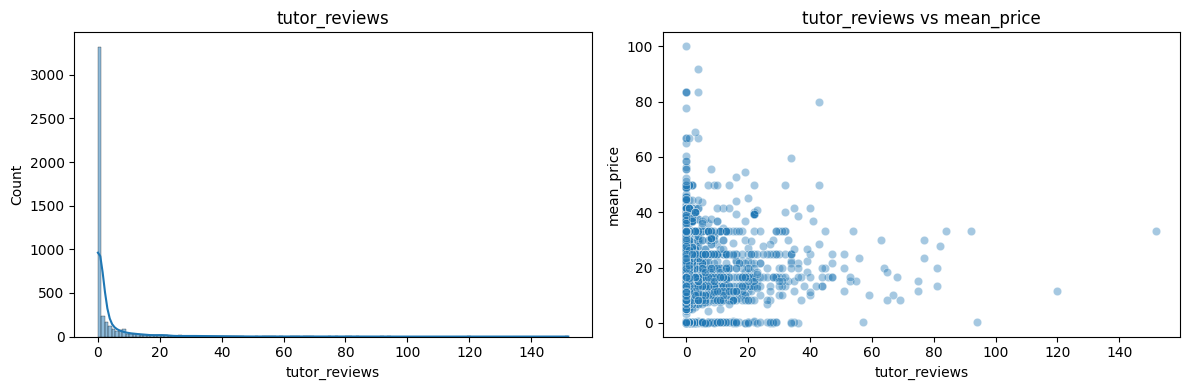

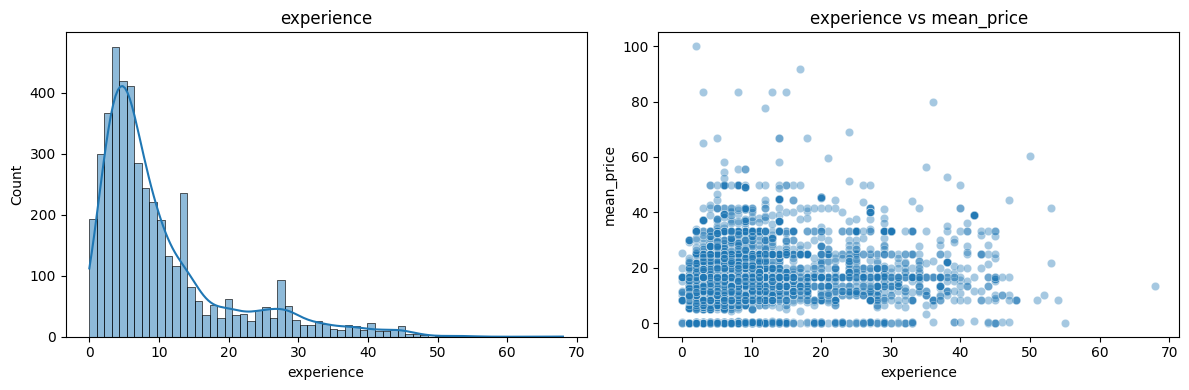

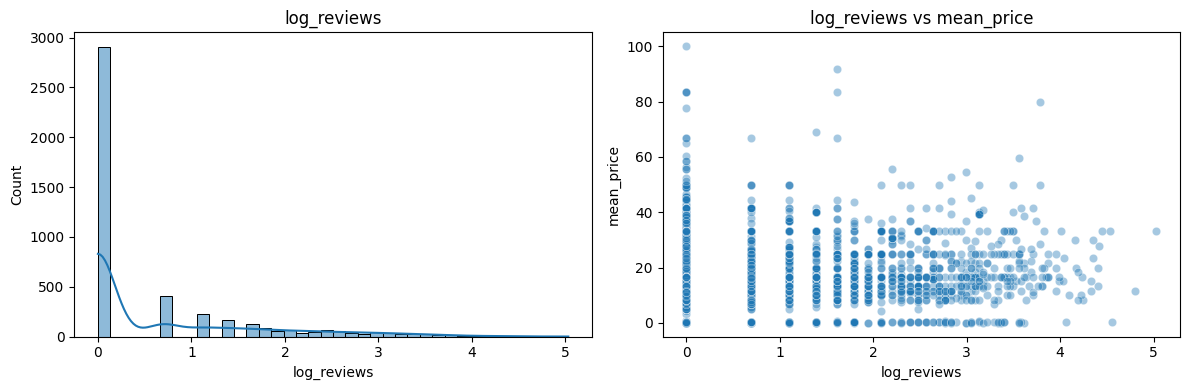

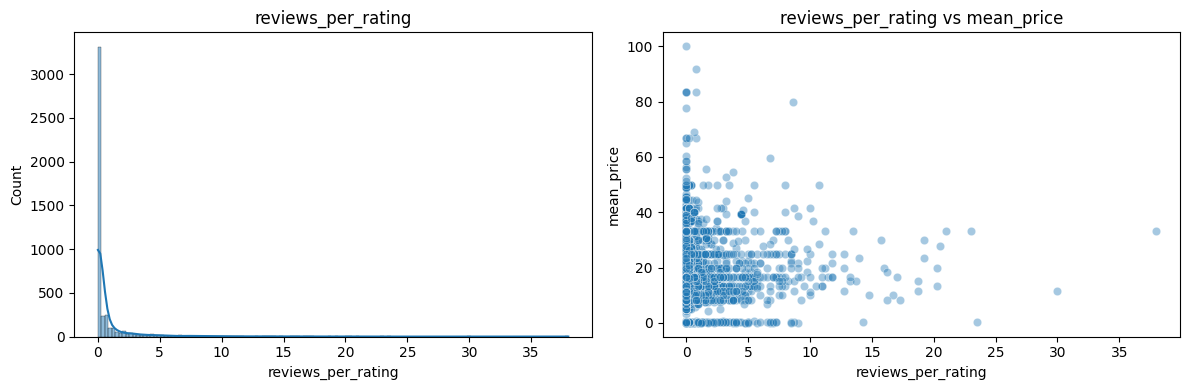

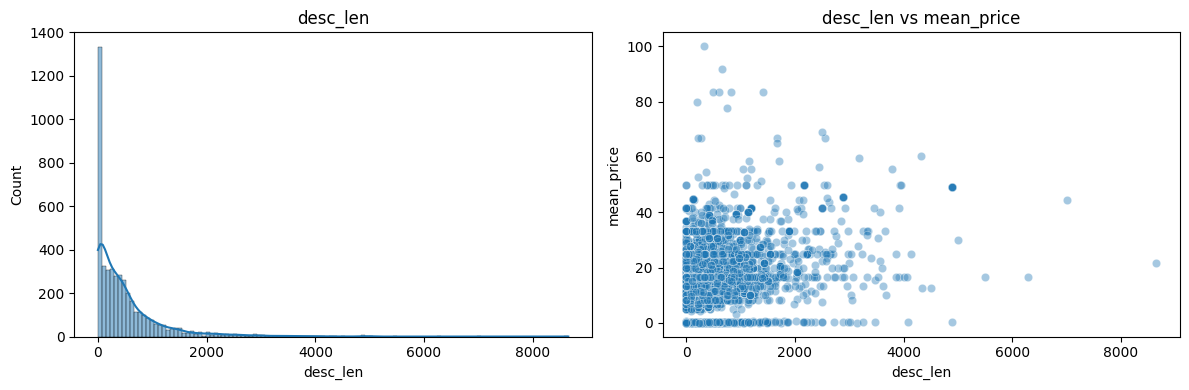

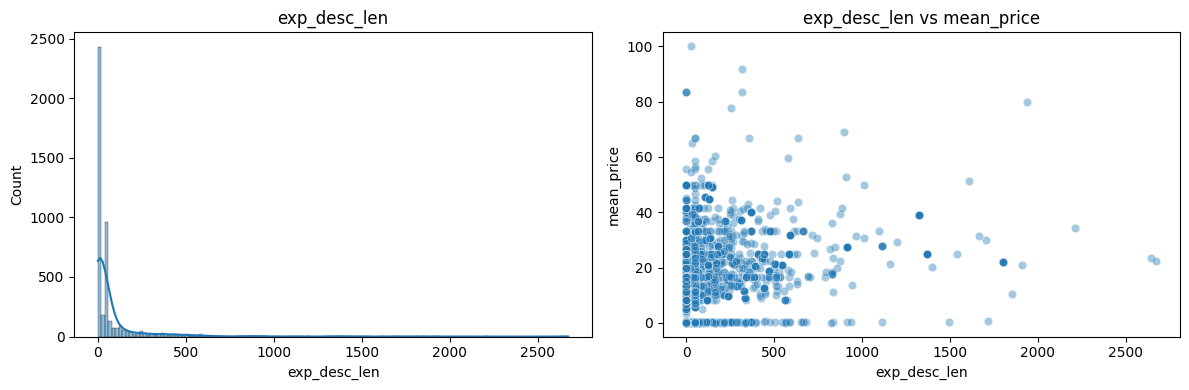

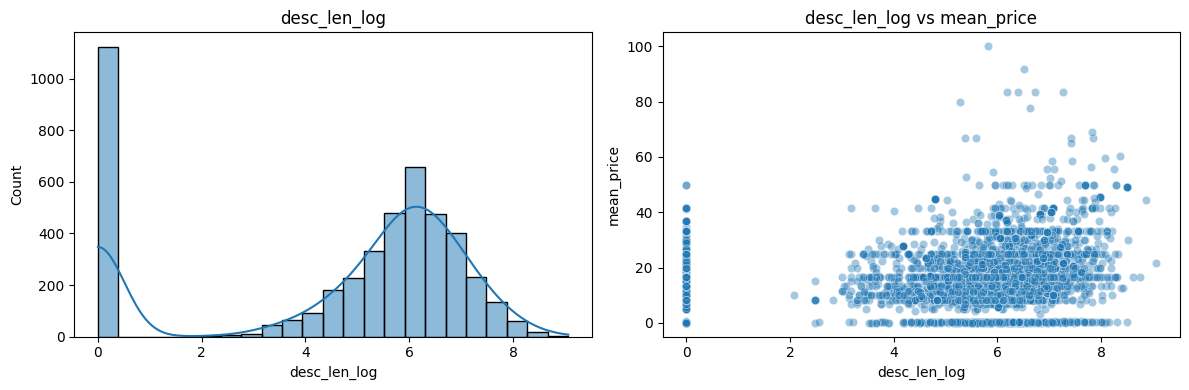

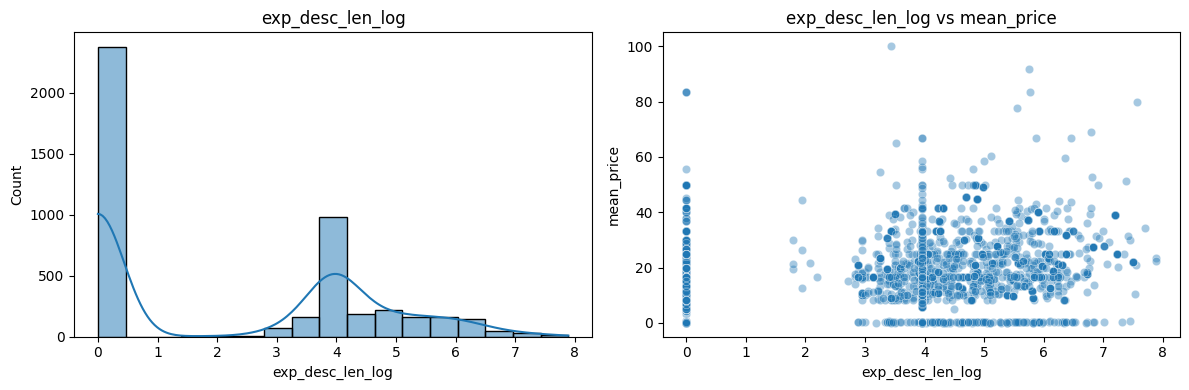

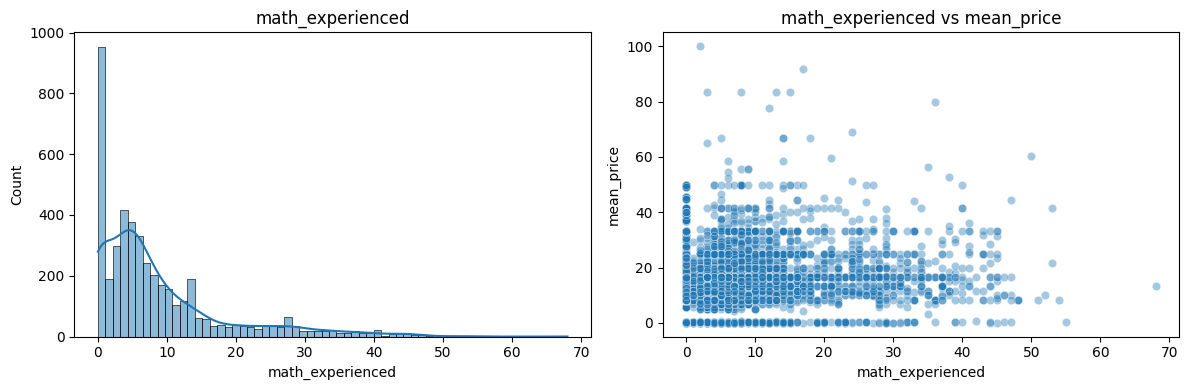

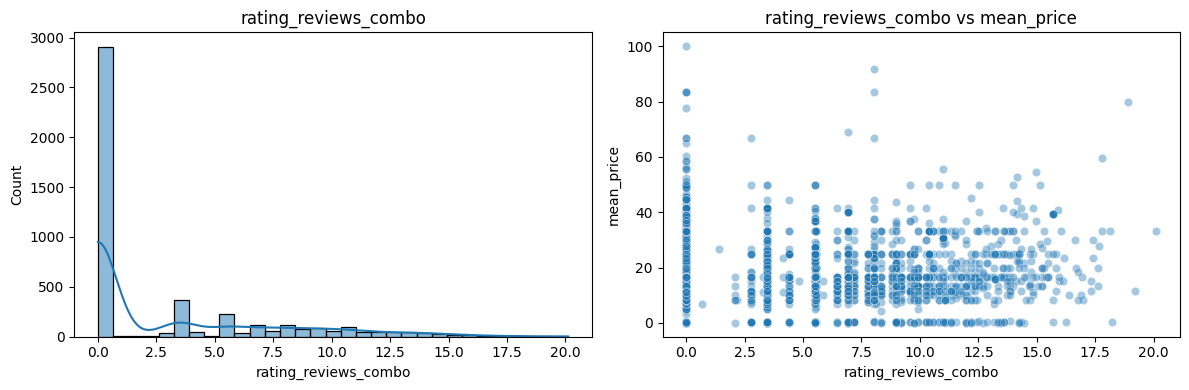

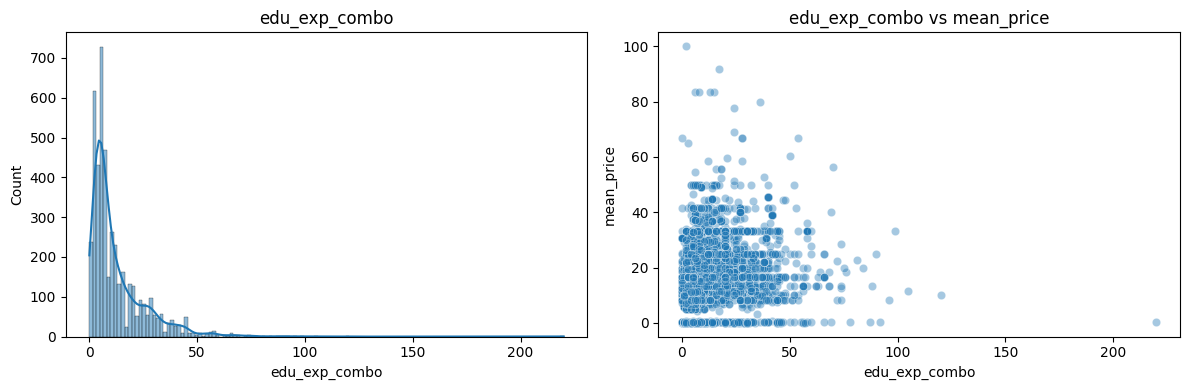

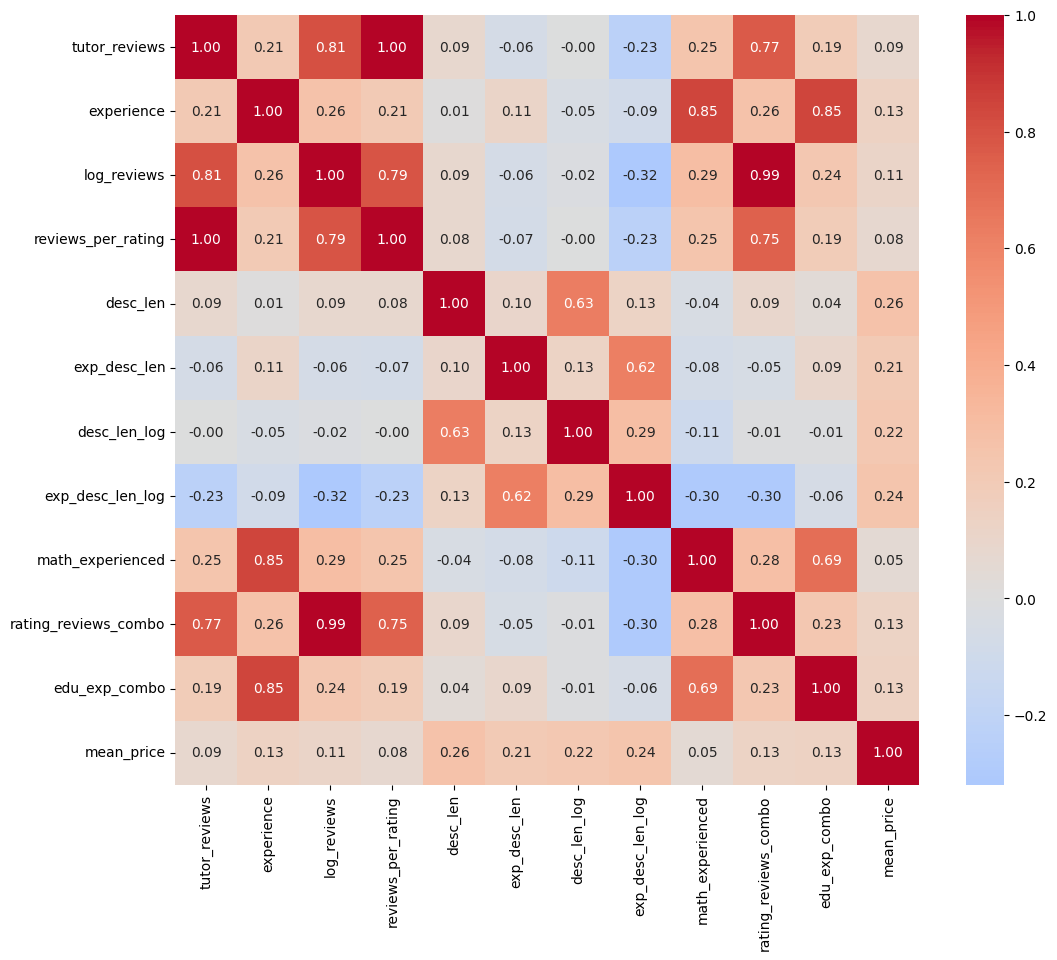


= Корреляционная матрица числовых признаков =
                      tutor_reviews  experience  log_reviews  \
tutor_reviews              1.000000    0.213903     0.805436   
experience                 0.213903    1.000000     0.260129   
log_reviews                0.805436    0.260129     1.000000   
reviews_per_rating         0.998384    0.210155     0.790254   
desc_len                   0.087077    0.010174     0.085762   
exp_desc_len              -0.064197    0.110816    -0.064740   
desc_len_log              -0.001367   -0.045935    -0.016035   
exp_desc_len_log          -0.227137   -0.091625    -0.319250   
math_experienced           0.251113    0.846354     0.293520   
rating_reviews_combo       0.768047    0.260335     0.991791   
edu_exp_combo              0.193087    0.846494     0.236053   
mean_price                 0.086597    0.134863     0.111878   

                      reviews_per_rating  desc_len  exp_desc_len  \
tutor_reviews                   0.998384  0.087077  

(                 feature      corr
 0          tutor_reviews  0.086597
 1             experience  0.134863
 2            log_reviews  0.111878
 3     reviews_per_rating  0.076923
 4               desc_len  0.260772
 5           exp_desc_len  0.208144
 6           desc_len_log  0.217301
 7       exp_desc_len_log  0.244001
 8       math_experienced  0.054612
 9   rating_reviews_combo  0.127573
 10         edu_exp_combo  0.134863,
 [('tutor_reviews', np.float64(0.08659658196048142)),
  ('experience', np.float64(0.1348627136256523)),
  ('log_reviews', np.float64(0.11187829508712574)),
  ('reviews_per_rating', np.float64(0.07692284851008165)),
  ('desc_len', np.float64(0.26077229788842565)),
  ('exp_desc_len', np.float64(0.2081443682214954)),
  ('desc_len_log', np.float64(0.2173014799200262)),
  ('exp_desc_len_log', np.float64(0.24400139124200826)),
  ('math_experienced', np.float64(0.054611616971652975)),
  ('rating_reviews_combo', np.float64(0.12757280337855598)),
  ('edu_exp_combo', np.

In [14]:
eda_numeric(TutorFeatureEngineer().transform(TutorDataCleaner().transform(train)))

### Анализ числовых переменных

Корреляционный анализ показал, что среди числовых признаков есть признаки с сильной мультиколлинеарностью: `tutor_reviews` и `reviews_per_rating` практически идентичны (корреляция 0.998), а `log_reviews` и `rating_reviews_combo` тоже сильно связаны (0.992). Кроме того, `experience`, `math_experienced` и `edu_exp_combo` взаимно коррелируют примерно на 0.85, что указывает на дублирование информации.  

Среди всех признаков наиболее сильное влияние на цену оказывают длина описания репетитора (`desc_len`, корреляция 0.261), логарифм длины описания опыта (`exp_desc_len_log`, 0.244) и логарифм общей длины описания (`desc_len_log`, 0.217). При этом опыт работы сам по себе влияет слабо (0.135), количество отзывов практически не отражается на цене (0.087), а комбинированный признак рейтинг × отзывы оказывает умеренное влияние (0.128).  

Исходя из этого, для построения модели разумно 
- **оставить** признаки 
    - `desc_len`, `exp_desc_len_log`, `experience` и `log_reviews`, 
- **исключить** признаки с высокой корреляцией и дублирующей информацией    
    - `reviews_per_rating`, `rating_reviews_combo`, `math_experienced` и `edu_exp_combo`.

В целом, анализ показывает, что для прогнозирования цены репетитора важнее качество презентации, чем фактические метрики опыта и отзывов.


In [15]:
final_df = run_eda_summary(TutorFeatureEngineer().transform(TutorDataCleaner().transform(train)), numerical_features=None)

EDA SUMMARY

=== БИНАРНЫЕ ПРИЗНАКИ ===
                feature  share_1  share_0      corr  abs_corr
           desc_has_ege 0.503958 0.496042  0.183748  0.183748
   has_description_long 0.725154 0.274846  0.178114  0.178114
        desc_has_school 0.627089 0.372911  0.173331  0.173331
       desc_has_results 0.273747 0.726253  0.163848  0.163848
has_university_students 0.705365 0.294635  0.163128  0.163128
    desc_has_experience 0.360378 0.639622  0.149659  0.149659
      info_with_reviews 0.051451 0.948549  0.146424  0.146424
       desc_has_quality 0.119833 0.880167  0.140306  0.140306
       has_degree_title 0.016711 0.983289  0.139295  0.139295
    desc_has_individual 0.258795 0.741205  0.134547  0.134547
        desc_has_online 0.238127 0.761873  0.126874  0.126874
           is_top10_uni 0.230651 0.769349  0.125763  0.125763
     has_additional_edu 0.171724 0.828276  0.119679  0.119679
                is_math 0.810246 0.189754 -0.110884  0.110884
         desc_has_price 0.05189

C:\Users\Asus\AppData\Local\Temp\ipykernel_1189452\2253401957.py:63: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  means = df.groupby(col)[target].mean()


### Анализ категориальных признаков

**Бинарные признаки**

**Специализация на ЕГЭ и работа с вузами** оказывают наибольшее влияние среди бинарных признаков (корр. 0.18-0.16). Наличие учёной степени, хоть и редкое (1.7%), также значимо (0.14). **Репрезентативность признаков невысока** — большинство имеет выраженный дисбаланс классов, что может ограничивать их информативность в моделях.

**Категориальные признаки**

**Количество ключевых слов (total_keywords)** демонстрирует наивысшую корреляцию среди всех признаков (0.263), подчёркивая важность полноты профиля. **Статус и сегмент** репетитора также значимы (0.24 и 0.21 соответственно). Однако сильная концентрация в доминирующих категориях (например, 81% репетиторов имеют одно образование) требует осторожного кодирования.

**Списковые признаки**

Анализ **отдельных элементов списков** показывает значимость специализации на **ЕГЭ и олимпиадах** (корр. 0.16-0.09), а также работы со **старшеклассниками и студентами**. Базовые школьные программы и младшие классы демонстрируют отрицательную корреляцию с ценой. Важно отметить, что **корреляционный анализ отдельных элементов не полностью отражает их роль в модели** — комбинации и взаимодействия могут оказаться более значимыми.

**Ключевые выводы для модели**

1. **Приоритетные признаки**: `total_keywords`, `desc_len`, `status`, `segment` — сильнее всего коррелируют с ценой

2. **Специализация ценится**: `desc_has_ege`, `has_university_students`, `desc_has_school` — ключевые бинарные признаки для включения

3. **Редкие признаки**: `has_degree_title`, `desc_has_quality` — требуют регуляризации из-за низкой встречаемости (1-12%)

### Итоговый набор признаков для модели

После анализа EDA сформирован сокращённый набор из 34 наиболее информативных признаков. Отбор основан на:
- корреляции с целевой переменной (> 0.1 для большинства признаков),
- устранении мультиколлинеарности (удалены дублирующие признаки),
- сохранении ключевых категорий: качество описания, специализация, статус.

Результат: Уменьшение размерности на ~30% при сохранении ключевой информации.

In [16]:
# ============================================
# ОКОНЧАТЕЛЬНЫЙ НАБОР ПРИЗНАКОВ ДЛЯ МОДЕЛИ
# ============================================

# Числовые признаки
NUM_FEATURES = [
    'experience',           # опыт работы
    'log_reviews',          # логарифм отзывов
    'desc_len',            # длина описания
    'exp_desc_len',        # длина описания опыта
    'desc_len_log',        # лог длины описания
    'exp_desc_len_log',    # лог длины описания опыта
    'num_tags',            # количество тегов
    'num_categories',      # количество категорий
    'num_educations',      # количество образований
    'reviews_per_rating',  # отзывы на рейтинг
]

# Бинарные признаки
BIN_FEATURES = [
    # Специализация
    'desc_has_ege',           # упоминание ЕГЭ
    'has_university_students', # работа с вузами
    'desc_has_school',        # упоминание школы
    'desc_has_results',       # упоминание результатов
    'has_ege_oge',           # подготовка к ЕГЭ/ОГЭ
    'has_school_program',    # школьная программа
    
    # Качество описания
    'has_description_long',   # длинное описание
    'desc_has_experience',    # опыт в описании
    'desc_has_quality',       # качество в описании
    'desc_has_individual',    # индивидуальный подход
    
    # Дополнительные
    'has_additional_edu',     # дополнительное образование
    'is_top10_uni',          # топ-10 ВУЗ
    'has_degree_title',      # учёная степень
    'is_math',               # преподаёт математику
    'gender',                # пол
    'has_rating',            # наличие рейтинга
    'has_reviews',           # наличие отзывов
]

# Категориальные признаки
CAT_FEATURES = [
    'status',            # статус репетитора
    'segment',           # сегмент
    'experience_group',  # группа по опыту
    'faculty',           # факультет
    'tutor_rating',      # рейтинг (как категория)
    'total_keywords',    # количество ключевых слов
]

# Признаки-списки (оставить как есть)
LST_FEATURES = [
    'categories_list',       # список категорий
    'tutor_head_tags_list',  # список тегов
]

# Итоговый список всех признаков
ALL_FEATURES = (
    NUM_FEATURES + 
    BIN_FEATURES + 
    CAT_FEATURES + 
    LST_FEATURES
)

# Целевая переменная
TARGET = 'mean_price'

print(f"Итоговый набор: {len(ALL_FEATURES)} признаков")
print(f"- Числовые: {len(NUM_FEATURES)}")
print(f"- Бинарные: {len(BIN_FEATURES)}")
print(f"- Категориальные: {len(CAT_FEATURES)}")
print(f"- Списковые: {len(LST_FEATURES)}")

Итоговый набор: 35 признаков
- Числовые: 10
- Бинарные: 17
- Категориальные: 6
- Списковые: 2


### Кодирование списковых категориальных признаков

Признаки `categories_list` и `tutor_head_tags_list` содержат списки тегов/категорий — каждый элемент списка является отдельной категорией.

Используем `MultiLabelBinarizerWrapper` для преобразования, сохранив информацию о специализации, автоматически отфильтровав редкие элементы.

In [17]:
class MultiLabelBinarizerWrapper(BaseEstimator, TransformerMixin):
    def __init__(self, min_freq=20, handle_unknown='ignore'):
        self.min_freq = min_freq
        self.handle_unknown = handle_unknown
        self.mlb = None
        self.frequent_labels = None
        
    def fit(self, X, y=None):
        # X приходит как DataFrame с 1 колонкой
        all_labels = X.iloc[:, 0].explode()
        freq = all_labels.value_counts()

        # оставляем только частые
        self.frequent_labels = freq[freq >= self.min_freq].index.tolist()

        self.mlb = MultiLabelBinarizer(classes=self.frequent_labels)
        self.mlb.fit(X.iloc[:, 0])
        return self
    
    def transform(self, X):
        # Преобразуем только известные метки
        transformed = self.mlb.transform(X.iloc[:, 0])
        return pd.DataFrame(
            transformed,
            columns=[f"mlb_{c}" for c in self.mlb.classes_],
            index=X.index
        )

In [18]:
# Сделала класс, чтобы было проще добавлять / исключать признаки (перед трансформацие проверяет наличие колонок в датасете)
class OptionalColumnTransformer(BaseEstimator, TransformerMixin):
    def __init__(self, transformer, column):
        self.transformer = transformer
        self.column = column
        
    def fit(self, X, y=None):
        if self.column in X.columns:
            self.transformer.fit(X[self.column], y)
        return self
    
    def transform(self, X):
        if self.column in X.columns:
            return self.transformer.transform(X[self.column])
        else:
            # вернуть пустой массив с правильной размерностью
            return np.zeros((len(X), 0))

### Универсальный препроцессор для всех типов признаков

Класс `Preprocessor` объединяет обработку всех типов признаков в единый пайплайн.

**Обработка по типам:**
- **Числовые**: медианное заполнение + стандартизация
- **Бинарные**: заполнение модальным значением (без масштабирования)
- **Категориальные**: заполнение модой + One-Hot кодирование
- **Списковые**: MultiLabelBinarizer с порогом частоты 30

**Ключевые особенности:**
- работает только с признаками, присутствующими в данных
- безопасен при кросс-валидации (динамический ColumnTransformer)
- подходит для любых моделей sklearn


In [19]:
class Preprocessor(BaseEstimator, TransformerMixin):
    
    numeric_pipe = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ])

    binary_pipe = Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent'))
    ])

    categorical_pipe = Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore'))
    ])

    def __init__(self, lst_features=None):
        self.lst_features = lst_features

    def fit(self, X, y=None):
        transformers = [
            ('num', self.numeric_pipe, NUM_FEATURES),
            ('bin', self.binary_pipe, BIN_FEATURES),
            ('cat', self.categorical_pipe, CAT_FEATURES),
            ('categories_mlb', MultiLabelBinarizerWrapper(min_freq=30), ['categories_list']),
            ('tags_mlb', MultiLabelBinarizerWrapper(min_freq=30), ['tutor_head_tags_list'])
        ]
        # выбираем только те колонки, которые есть в X
        safe_transformers = []
        for name, trans, cols in transformers:
            cols_exist = [c for c in cols if c in X.columns]
            if cols_exist:
                safe_transformers.append((name, trans, cols_exist))

        self.ct = ColumnTransformer(safe_transformers, remainder='drop')
        self.ct.fit(X, y)
        return self

    def transform(self, X):
        return self.ct.transform(X)

### Первичный отбор моделей для прогнозирования цены

Для определения наиболее перспективных алгоритмов проведено сравнение 8 моделей разных семейств: линейные (Ridge, Lasso, ElasticNet), ансамблевые на деревьях (RandomForest, GradientBoosting) и градиентный бустинг (XGBoost, LightGBM, CatBoost). Каждая модель обучается в едином пайплайне, включающем очистку данных, генерацию признаков и предобработку. Оценка выполняется по трём метрикам: MAE (средняя абсолютная ошибка в руб/мин), MSE и R². Первичный отбор позволяет выявить модели с наилучшим базовым качеством для последующего подбора гиперпараметров.

In [20]:
models = {
    'Ridge': Ridge(alpha=1.0),
    'Lasso': Lasso(alpha=0.01),
    'ElasticNet': ElasticNet(alpha=0.01, l1_ratio=0.5),
    'RandomForest': RandomForestRegressor(
        n_estimators=200,
        max_depth=10,
        random_state=42,
        n_jobs=-1
    ),
    'GradientBoosting': GradientBoostingRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    ),
    "XGBoost": XGBRegressor(random_state=42, n_jobs=-1),
    "LightGBM": LGBMRegressor(random_state=42, n_jobs=-1),
    "CatBoost": CatBoostRegressor(random_state=42, verbose=0)
}


In [21]:
def evaluate_models(models, X_train, X_valid, y_train, y_valid, feat_lst=None):
    results = []

    for name, model in models.items():
        pipe = Pipeline([
            ('cleaner', TutorDataCleaner()),
            ('feature_engineering', TutorFeatureEngineer(feat_lst)),
            ('prep', Preprocessor(feat_lst)),
          #  ('selector', SelectKBest(score_func=f_regression, k=30)),
            ('model', model)
        ])

        pipe.fit(X_train, y_train)
        y_pred = pipe.predict(X_valid)

        results.append({
            'model': name,
            'MAE': mean_absolute_error(y_valid, y_pred),
            'MSE': mean_squared_error(y_valid, y_pred),
            'R2': r2_score(y_valid, y_pred)
        })

    return pd.DataFrame(results).sort_values('MAE')


In [22]:

y = train[TARGET]
X = train.drop(columns=[TARGET])


X_train, X_valid, y_train, y_valid = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

results = evaluate_models(
    models=models,
    X_train=X_train,
    X_valid=X_valid,
    y_train=y_train,
    y_valid=y_valid, 
    feat_lst=ALL_FEATURES#NUM_FEATURES + BIN_FEATURES + CAT_FEATURES + LST_FEATURES
)

results


c:\Users\Asus\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_label.py:909: UserWarning: unknown class(es) ['Взрослые кроме абитуриентов и студентов в паре', 'Взрослые кроме абитуриентов и студентов группа', 'Дошкольники в паре', 'Дошкольники группа', 'Студенты университетов в паре', 'Школьники с 1 по 4 класс группа'] will be ignored
  warnings.warn(
c:\Users\Asus\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_label.py:909: UserWarning: unknown class(es) ['A-level', 'GMAT (математическая часть)', 'Mathematik auf Deutsch'] will be ignored
  warnings.warn(
c:\Users\Asus\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_label.py:909: UserWarning: unknown class(es) ['Взрослые кроме абитуриентов и студентов в паре', 'Взрослые кроме абитуриентов и студентов группа', 'Дошкольники в паре', 'Дошкольники группа', 'Студенты университетов в паре', 'Школьники с 1 по 4 класс группа'] will be ignored
  w

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.024226 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1373
[LightGBM] [Info] Number of data points in the train set: 3638, number of used features: 93
[LightGBM] [Info] Start training from score 16.156535


c:\Users\Asus\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_label.py:909: UserWarning: unknown class(es) ['Взрослые кроме абитуриентов и студентов в паре', 'Студенты университетов в паре', 'Школьники с 1 по 4 класс группа'] will be ignored
  warnings.warn(
c:\Users\Asus\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_label.py:909: UserWarning: unknown class(es) ['A-level', 'GMAT (математическая часть)', 'Mathematik auf Deutsch'] will be ignored
  warnings.warn(
c:\Users\Asus\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
c:\Users\Asus\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_label.py:909: UserWarning: unknown class(es) ['Взрослые кроме абитуриентов и студентов в паре', 'Взрослые кроме абитуриентов и студентов группа', 'Дош

,model,MAE,MSE,R2
3,RandomForest,6.053463,89.546499,0.241039
7,CatBoost,6.106142,91.177494,0.227216
6,LightGBM,6.196443,94.178819,0.201778
4,GradientBoosting,6.322548,94.128960,0.202200
5,XGBoost,6.439163,99.049056,0.160500
1,Lasso,6.488732,93.201706,0.210059
2,ElasticNet,6.490401,93.581993,0.206836
0,Ridge,6.543097,94.144749,0.202066


### Вывод по первичному отбору моделей

**Ключевые наблюдения**
1. **Градиентный бустинг демонстрирует наилучшие результаты** — CatBoost и LightGBM показывают минимальные MAE
2. **RandomForest показывает лучший MSE** (90.944) — оптимален для Kaggle, где метрика — MSE
3. **Линейные модели уступают ансамблевым** — разница в MAE составляет ~0.5 руб/мин (8%)

**Итог**

Подбор гиперпараметров будет осуществляться для трёх моделей:
- RandomForest — приоритет для Kaggle (лучший MSE)
- CatBoost — лучший MAE и сбалансированные метрики
- LightGBM — близкий к CatBoost результат с потенциально лучшей скоростью обучения

In [23]:
def tune_model(model_name, base_model, param_dist, X_train, y_train, cv=3, n_iter=20):  
    # Создаем пайплайн
    pipe = Pipeline([
        ('cleaner', TutorDataCleaner()),
        ('feature_engineering', TutorFeatureEngineer(ALL_FEATURES)),
        ('prep', Preprocessor(ALL_FEATURES)),
        ('model', base_model)
    ])
    
    # Запускаем случайный поиск
    search = RandomizedSearchCV(
        pipe, 
        param_dist, 
        n_iter=n_iter,
        cv=cv,
        scoring='neg_mean_squared_error',  # Оптимизируем MSE для Kaggle
        n_jobs=-1,
        verbose=1,
        random_state=42
    )
    
    print(f"🔍 Подбор параметров для {model_name}...")
    search.fit(X_train, y_train)
    
    print(f"Лучший MSE: {-search.best_score_:.4f}")
    print(f"Лучшие параметры:")
    for param, value in search.best_params_.items():
        print(f"  {param}: {value}")
    
    return search.best_estimator_, search.best_params_

# ПАРАМЕТРЫ ДЛЯ ПОИСКА
# ============================================

# Для RandomForest (лучший MSE)
rf_params = {
    'model__n_estimators': [100, 200, 300, 400],
    'model__max_depth': [5, 10, 15, 20, None],
    'model__min_samples_split': [2, 5, 10],
    'model__min_samples_leaf': [1, 2, 4],
    'model__max_features': ['sqrt', 'log2', 0.5, 0.7]
}

# Для CatBoost (лучший MAE)
catboost_params = {
    'model__iterations': [500, 1000, 1500],
    'model__depth': [4, 6, 8, 10],
    'model__learning_rate': [0.01, 0.03, 0.05, 0.1],
    'model__l2_leaf_reg': [1, 3, 5, 7]
}

# Для LightGBM (баланс скорости и качества)
lgbm_params = {
    'model__n_estimators': [200, 300, 500],
    'model__max_depth': [3, 5, 7, -1],
    'model__learning_rate': [0.01, 0.05, 0.1],
    'model__num_leaves': [31, 63, 127],
    'model__min_child_samples': [20, 50, 100]
}

# ЗАПУСК ПОДБОРА ПАРАМЕТРОВ
# ============================================

# Подготавливаем данные
y = train[TARGET]
X = train.drop(columns=[TARGET])

# Разделяем на обучающую и валидационную выборки
X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Словарь для хранения настроенных моделей
tuned_models = {}

# 1. Настраиваем RandomForest
print("\n" + "="*60)
best_rf, rf_best_params = tune_model(
    'RandomForest',
    RandomForestRegressor(random_state=42, n_jobs=-1),
    rf_params,
    X_train, y_train,
    n_iter=25
)
tuned_models['RandomForest'] = best_rf

# 2. Настраиваем CatBoost
print("\n" + "="*60)
best_catboost, cb_best_params = tune_model(
    'CatBoost',
    CatBoostRegressor(random_state=42, verbose=0),
    catboost_params,
    X_train, y_train,
    n_iter=20
)
tuned_models['CatBoost'] = best_catboost

# 3. Настраиваем LightGBM
print("\n" + "="*60)
best_lgbm, lgbm_best_params = tune_model(
    'LightGBM',
    LGBMRegressor(random_state=42, n_jobs=-1, verbose=-1),
    lgbm_params,
    X_train, y_train,
    n_iter=20
)
tuned_models['LightGBM'] = best_lgbm

# СРАВНЕНИЕ НАСТРОЕННЫХ МОДЕЛЕЙ
# ============================================

print("\n" + "="*60)
print("РЕЗУЛЬТАТЫ НАСТРОЕННЫХ МОДЕЛЕЙ НА ВАЛИДАЦИИ")
print("="*60)

results = []
for name, model in tuned_models.items():
    # Предсказания на валидационной выборке
    y_pred = model.predict(X_valid)
    
    results.append({
        'model': name,
        'MAE': mean_absolute_error(y_valid, y_pred),
        'MSE': mean_squared_error(y_valid, y_pred),
        'R2': r2_score(y_valid, y_pred)
    })

# Создаем и выводим таблицу результатов
results_df = pd.DataFrame(results).sort_values('MSE')
print(results_df.to_string(index=False))

# Сохраняем лучшую модель (по MSE)
best_model_name = results_df.iloc[0]['model']
best_model = tuned_models[best_model_name]
print(f"\nЛУЧШАЯ МОДЕЛЬ: {best_model_name} (MSE: {results_df.iloc[0]['MSE']:.4f})")


🔍 Подбор параметров для RandomForest...
Fitting 3 folds for each of 25 candidates, totalling 75 fits


c:\Users\Asus\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_label.py:909: UserWarning: unknown class(es) ['Взрослые кроме абитуриентов и студентов в паре', 'Взрослые кроме абитуриентов и студентов группа', 'Дошкольники в паре', 'Дошкольники группа', 'Студенты университетов в паре', 'Школьники с 1 по 4 класс группа'] will be ignored
  warnings.warn(
c:\Users\Asus\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_label.py:909: UserWarning: unknown class(es) ['A-level', 'GMAT (математическая часть)', 'Mathematik auf Deutsch'] will be ignored
  warnings.warn(
c:\Users\Asus\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_label.py:909: UserWarning: unknown class(es) ['Взрослые кроме абитуриентов и студентов в паре', 'Взрослые кроме абитуриентов и студентов группа', 'Дошкольники в паре', 'Дошкольники группа', 'Студенты университетов в паре', 'Школьники с 1 по 4 класс группа'] will be ignored
  w

Лучший MSE: 79.5577
Лучшие параметры:
  model__n_estimators: 100
  model__min_samples_split: 5
  model__min_samples_leaf: 2
  model__max_features: sqrt
  model__max_depth: 20

🔍 Подбор параметров для CatBoost...
Fitting 3 folds for each of 20 candidates, totalling 60 fits


c:\Users\Asus\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_label.py:909: UserWarning: unknown class(es) ['Взрослые кроме абитуриентов и студентов в паре', 'Взрослые кроме абитуриентов и студентов группа', 'Дошкольники в паре', 'Дошкольники группа', 'Студенты университетов в паре', 'Школьники с 1 по 4 класс группа'] will be ignored
  warnings.warn(
c:\Users\Asus\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_label.py:909: UserWarning: unknown class(es) ['A-level', 'GMAT (математическая часть)', 'Mathematik auf Deutsch'] will be ignored
  warnings.warn(
c:\Users\Asus\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_label.py:909: UserWarning: unknown class(es) ['Взрослые кроме абитуриентов и студентов в паре', 'Взрослые кроме абитуриентов и студентов группа', 'Дошкольники в паре', 'Дошкольники группа', 'Студенты университетов в паре', 'Школьники с 1 по 4 класс группа'] will be ignored
  w

Лучший MSE: 79.6687
Лучшие параметры:
  model__learning_rate: 0.01
  model__l2_leaf_reg: 1
  model__iterations: 1000
  model__depth: 8

🔍 Подбор параметров для LightGBM...
Fitting 3 folds for each of 20 candidates, totalling 60 fits


c:\Users\Asus\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_label.py:909: UserWarning: unknown class(es) ['Взрослые кроме абитуриентов и студентов в паре', 'Взрослые кроме абитуриентов и студентов группа', 'Дошкольники в паре', 'Дошкольники группа', 'Студенты университетов в паре', 'Школьники с 1 по 4 класс группа'] will be ignored
  warnings.warn(
c:\Users\Asus\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_label.py:909: UserWarning: unknown class(es) ['A-level', 'GMAT (математическая часть)', 'Mathematik auf Deutsch'] will be ignored
  warnings.warn(
c:\Users\Asus\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_label.py:909: UserWarning: unknown class(es) ['Взрослые кроме абитуриентов и студентов в паре', 'Взрослые кроме абитуриентов и студентов группа', 'Дошкольники в паре', 'Дошкольники группа', 'Студенты университетов в паре', 'Школьники с 1 по 4 класс группа'] will be ignored
  w

Лучший MSE: 82.1874
Лучшие параметры:
  model__num_leaves: 127
  model__n_estimators: 200
  model__min_child_samples: 20
  model__max_depth: 7
  model__learning_rate: 0.05

РЕЗУЛЬТАТЫ НАСТРОЕННЫХ МОДЕЛЕЙ НА ВАЛИДАЦИИ


c:\Users\Asus\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_label.py:909: UserWarning: unknown class(es) ['Взрослые кроме абитуриентов и студентов в паре', 'Студенты университетов в паре', 'Школьники с 1 по 4 класс группа'] will be ignored
  warnings.warn(
c:\Users\Asus\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_label.py:909: UserWarning: unknown class(es) ['A-level', 'GMAT (математическая часть)', 'Mathematik auf Deutsch'] will be ignored
  warnings.warn(
c:\Users\Asus\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_label.py:909: UserWarning: unknown class(es) ['Взрослые кроме абитуриентов и студентов в паре', 'Студенты университетов в паре', 'Школьники с 1 по 4 класс группа'] will be ignored
  warnings.warn(
c:\Users\Asus\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_label.py:909: UserWarning: unknown class(es) ['A-level', 'GMAT (математическая 

       model      MAE       MSE       R2
    CatBoost 6.063821 89.462739 0.241749
RandomForest 5.937947 90.603561 0.232080
    LightGBM 6.141754 91.540307 0.224141

ЛУЧШАЯ МОДЕЛЬ: CatBoost (MSE: 89.4627)


c:\Users\Asus\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_label.py:909: UserWarning: unknown class(es) ['Взрослые кроме абитуриентов и студентов в паре', 'Студенты университетов в паре', 'Школьники с 1 по 4 класс группа'] will be ignored
  warnings.warn(
c:\Users\Asus\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_label.py:909: UserWarning: unknown class(es) ['A-level', 'GMAT (математическая часть)', 'Mathematik auf Deutsch'] will be ignored
  warnings.warn(
c:\Users\Asus\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


### Результаты подбора гиперпараметров

Лучшие модели после настройки:
- CatBoost — MSE: 89.46, MAE: 6.06, R²: 0.242
- RandomForest — MSE: 90.60, MAE: 5.94, R²: 0.232
- LightGBM — MSE: 91.54, MAE: 6.14, R²: 0.224

Ключевые изменения после настройки:
- Качество моделей значительно улучшилось: MSE снизился с ~91 до ~89 (улучшение на 2-3%)
- RandomForest показал лучший MAE (5.94), но уступил CatBoost по MSE
- CatBoost стал лидером по MSE — критично для Kaggle

In [24]:
# Берем лучшую модель (RandomForest из настроенных)
best_pipeline = tuned_models['CatBoost']

print("Обучение на полном train...")
best_pipeline.fit(train, train[TARGET])

print("Делаем предсказания на test...")
test_predictions = best_pipeline.predict(test)

# Создаем submission файл
submission = pd.DataFrame({
    'index': test.index,
    'mean_price': test_predictions
})

# Сохраняем
submission_path = 'submission.csv'
submission.to_csv(submission_path, index=False)
print(f"Submission сохранен в: {submission_path}")

print("\nСтатистика предсказаний:")
print(submission['mean_price'].describe().round(2))

Обучение на полном train...


c:\Users\Asus\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_label.py:909: UserWarning: unknown class(es) ['Взрослые кроме абитуриентов и студентов в паре', 'Взрослые кроме абитуриентов и студентов группа', 'Дошкольники в паре', 'Дошкольники группа', 'Студенты университетов в паре', 'Школьники с 1 по 4 класс группа'] will be ignored
  warnings.warn(
c:\Users\Asus\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_label.py:909: UserWarning: unknown class(es) ['A-level', 'Mathematik auf Deutsch'] will be ignored
  warnings.warn(
c:\Users\Asus\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_label.py:909: UserWarning: unknown class(es) ['Взрослые кроме абитуриентов и студентов в паре', 'Взрослые кроме абитуриентов и студентов группа', 'Дошкольники в паре', 'Дошкольники группа', 'Студенты университетов в паре', 'Школьники с 1 по 4 класс группа'] will be ignored
  warnings.warn(
c:\Users\Asus\App

Делаем предсказания на test...
Submission сохранен в: submission.csv

Статистика предсказаний:
count    1516.00
mean       16.23
std         5.19
min         6.80
25%        12.88
50%        15.05
75%        18.50
max        44.90
Name: mean_price, dtype: float64


c:\Users\Asus\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_label.py:909: UserWarning: unknown class(es) ['Взрослые кроме абитуриентов и студентов в паре', 'Дошкольники в паре', 'Дошкольники группа', 'Студенты университетов в паре', 'Студенты университетов группа', 'Школьники с 1 по 4 класс группа'] will be ignored
  warnings.warn(
c:\Users\Asus\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_label.py:909: UserWarning: unknown class(es) ['A-level', 'Mathematik auf Deutsch'] will be ignored
  warnings.warn(


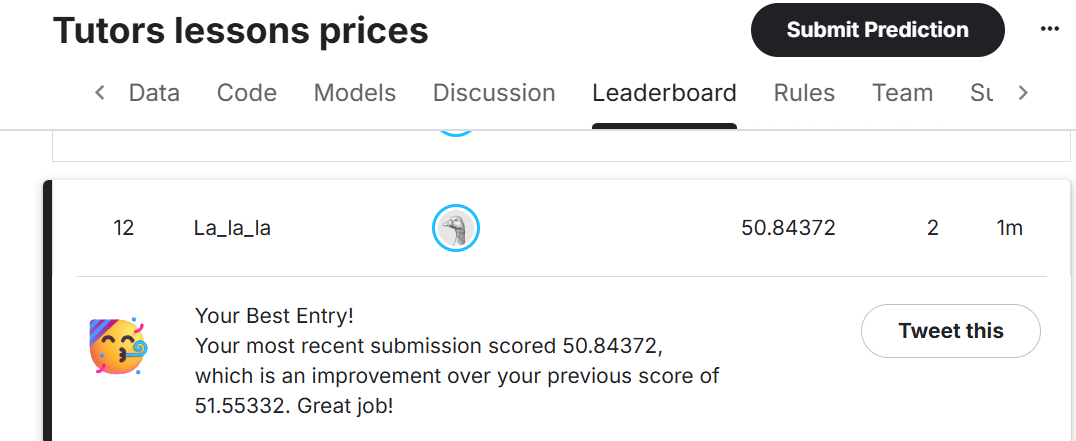

### Результаты

RandomForest показал наилучшее качество на Kaggle с MSE **50.84** против 51.55 у CatBoost. Несмотря на то, что CatBoost демонстрировал лучший MSE на локальной валидации, RandomForest оказался более стабильным на новых данных. Это подтверждается его лучшим MAE (5.94 против 6.06) на валидации, что указывает на меньшую дисперсию ошибок. 

Таким образом, RandomForest не только лучше обобщается, но и даёт более предсказуемые и устойчивые результаты на неизвестных данных, что критически важно для реальных применений.
